# Design a working controller

## 1. Set up the notebook

### 1.1 Do imports

Do imports.

In [47]:
import numpy as np
import sympy as sym
from scipy import linalg
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *
from ae483.design import *

### 1.2 Create an LQR solver

Define a function that solves the linear quadratic regulator (LQR) problem.

In [48]:
def lqr(A, B, Q, R):
    P = linalg.solve_continuous_are(A, B, Q, R)
    K = linalg.inv(R) @  B.T @ P
    return K

## 2. Derive equations of motion

### 2.1 Define symbolic variables

Define states.

In [49]:
# components of position (meters)
p_x, p_y, p_z = sym.symbols('p_x, p_y, p_z')

# yaw, pitch, and roll angles (radians)
psi, theta, phi = sym.symbols('psi, theta, phi')

# components of linear velocity (meters / second)
v_x, v_y, v_z = sym.symbols('v_x, v_y, v_z')

# components of angular velocity (radians / second)
w_x, w_y, w_z = sym.symbols('w_x, w_y, w_z')

tau_x, tau_y = sym.symbols('tau_x, tau_y')

e_x, e_y, e_z = sym.symbols('e_x, e_y, e_z')

Define inputs.

In [50]:
# components of net rotor torque
tau_z = sym.symbols('tau_z')

tau_x_cmd, tau_y_cmd = sym.symbols('tau_x_cmd, tau_y_cmd')

# net rotor force
f_z = sym.symbols('f_z')

Define parameters.

In [51]:
m, J_x, J_y, J_z, g , T_F= sym.symbols('m, J_x, J_y, J_z, g, T_F')

Create the linear velocity vector $v^B_{W, B}$ and the angular velocity vector $w^B_{W, B}$, both written in the coordinates of the body frame.

In [52]:
v_inB_ofWB = sym.Matrix([v_x, v_y, v_z])
w_inB_ofWB = sym.Matrix([w_x, w_y, w_z])

Create moment of inertia matrix (in coordinates of the body frame).

In [53]:
J_inB = sym.diag(J_x, J_y, J_z)

### 2.2 Define kinematics of orientation

#### 2.2.1 Rotation matrix in terms of yaw, pitch, roll angles

Define individual rotation matrices.

In [54]:
Rz = sym.Matrix([[sym.cos(psi), -sym.sin(psi), 0],
                 [sym.sin(psi), sym.cos(psi), 0],
                 [0, 0, 1]])

Ry = sym.Matrix([[sym.cos(theta), 0, sym.sin(theta)],
                 [0, 1, 0],
                 [-sym.sin(theta), 0, sym.cos(theta)]])

Rx = sym.Matrix([[1, 0, 0],
                 [0, sym.cos(phi), -sym.sin(phi)],
                 [0, sym.sin(phi), sym.cos(phi)]])

Apply sequential transformation to compute the rotation matrix that describes the orientation of the drone (i.e., of frame $B$ in the coordinates of frame $W$).

In [55]:
R_inW_ofB = Rz @ Ry @ Rx

#### 2.2.2 Map from angular velocity to angular rates

Recall that

$$\begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix} = N w_{W, B}^{B}$$

for some matrix $N$. Here is how to compute that matrix for a ZYX (yaw, pitch, roll) Euler angle sequence.  First, we compute its inverse:

In [56]:
Ninv = sym.Matrix.hstack((Ry @ Rx).T @ sym.Matrix([0, 0, 1]),
                              (Rx).T @ sym.Matrix([0, 1, 0]),
                                       sym.Matrix([1, 0, 0]))

Then, we compute $N$ by taking the inverse of $N^{-1}$:

In [57]:
N = sym.simplify(Ninv.inv())

### 2.3 Define equations of motion

Forces.

In [58]:
f_inB = R_inW_ofB.T @ sym.Matrix([0, 0, -m * g]) + sym.Matrix([0, 0, f_z])

Torques.

In [59]:
tau_inB = sym.Matrix([tau_x, tau_y, tau_z])

Create equations of motion.

In [60]:
f_sym = sym.Matrix.vstack(
    R_inW_ofB @ v_inB_ofWB,
    N @ w_inB_ofWB,
    (1 / m) * (f_inB - w_inB_ofWB.cross(m * v_inB_ofWB)),
    J_inB.inv() @ (tau_inB - w_inB_ofWB.cross(J_inB @ w_inB_ofWB)),
    sym.Matrix([(1/T_F)*(tau_x_cmd - tau_x),
                (1/T_F)*(tau_y_cmd - tau_y)]),
    sym.Matrix([p_x, p_y, p_z])
)

Show the right-hand side of the equations of motion, which have the form

$$\dot{s} = f(s, i, p)$$

for states

$$
s = \begin{bmatrix} p_x \\ p_y \\ p_z \\ \psi \\ \theta \\ \phi \\ v_x \\ v_y \\ v_z \\ w_x \\ w_y \\ w_z \\ \tau_x \\ \tau_y \\ e_x \\ e_y \\ e_z \end{bmatrix},
$$

inputs
$$
i = \begin{bmatrix} \tau_{x_{cmd}} \\ \tau_{y_{cmd}} \\ \tau_z \\ f_z \end{bmatrix},
$$

and parameters
$$
p = \begin{bmatrix} m \\ J_x \\ J_y \\ J_z \\ g \\ T_F \end{bmatrix}.
$$

In [61]:
f_sym

Matrix([
[ v_x*cos(psi)*cos(theta) + v_y*(sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(phi)) + v_z*(sin(phi)*sin(psi) + sin(theta)*cos(phi)*cos(psi))],
[v_x*sin(psi)*cos(theta) + v_y*(sin(phi)*sin(psi)*sin(theta) + cos(phi)*cos(psi)) + v_z*(-sin(phi)*cos(psi) + sin(psi)*sin(theta)*cos(phi))],
[                                                                       -v_x*sin(theta) + v_y*sin(phi)*cos(theta) + v_z*cos(phi)*cos(theta)],
[                                                                                         w_y*sin(phi)/cos(theta) + w_z*cos(phi)/cos(theta)],
[                                                                                                               w_y*cos(phi) - w_z*sin(phi)],
[                                                                                   w_x + w_y*sin(phi)*tan(theta) + w_z*cos(phi)*tan(theta)],
[                                                                                                (g*m*sin(theta) + m*v_y*w_z - m*v_z*w_y)/m

## 3. Derive state-space model

### 3.1 Choose equilibrium point

An equilibrium point of the nonlinear system is a choice of states $s_\text{eq}$ and inputs $i_\text{eq}$ — along with constant parameters $p_\text{eq}$ — for which

$$0 = f(s_\text{eq}, i_\text{eq}, p_\text{eq}).$$

Create a list of states, inputs, and parameters as symbolic variables.

In [62]:
s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
i = [tau_x_cmd, tau_y_cmd, tau_z, f_z]
p = [m, J_x, J_y, J_z, g, T_F]

Create a list of states to track as symbolic variables. These are states whose desired values will be specified by a client.

In [63]:
s_with_des = [p_x, p_y, p_z]

Create a function that evaluates $f(\cdot)$ at particular values of $s$, $i$, and $p$.

In [64]:
f = sym.lambdify(s + i + p, f_sym)

Define constants.

In [65]:
# Mass
m = 0.034     # <-- fixed

# Principle moments of inertia
J_x = 5.05e-5  # <-- fixed
J_y = 5.14e-5  # <-- fixed
J_z = 4.42e-5  # <-- fixed

T_F = .064

# Acceleration of gravity
g = 9.81

Create a list of parameter values in the **same order** as the symbolic list. These are the parameter estimates we found in our experiments. They are not choices. (We use the subscript `_eq` to be consistent with what follows, and could say "parameter values *at equilibrium*," but don't be misled. These parameter values are *given* and are *constant* - again, they aren't choices.)

In [66]:
p_eq = [m, J_x, J_y, J_z, g, T_F]

Create a list of state and input values at equilibrium in the **same order** as the symbolic lists.

In [67]:
s_eq = [0., 0., 0, 0., 0., 0., 0., 0., 0., 0., 0., 0., 0, 0, 0, 0, 0] # <-- fixed?
i_eq = [0., 0., 0., m * g]                                 # <-- fixed?

Evaluate the equations of motion at the equilibrium point — if it actually *is* an equilibrium point, then the result should be an array of zeros:

In [68]:
print(f(*s_eq, *i_eq, *p_eq))
assert(np.allclose(f(*s_eq, *i_eq, *p_eq), 0.))

[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]


Note that this equilibrium point would remain an equilibrium point for any choice of `p_x`, `p_y`, and `p_z` — that is one thing that allows the controller to track desired values of these variables.

### 3.2 Compute A and B

We want to find

$$
A = \frac{\partial f}{\partial s}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}
\qquad\text{and}\qquad
B = \frac{\partial f}{\partial i}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}.
$$

First, we compute each Jacobian (i.e., each matrix of partial derivatives) in symbolic form.

In [69]:
A_sym = f_sym.jacobian(s)
B_sym = f_sym.jacobian(i)

Then, we create functions that allow us to evaluate these Jacobians at particular values of $s$, $i$, and $p$.

In [70]:
A_num = sym.lambdify(s + i + p, A_sym)
B_num = sym.lambdify(s + i + p, B_sym)

Finally, we plug in our equilibrium point.

In [71]:
A = A_num(*s_eq, *i_eq, *p_eq)
B = B_num(*s_eq, *i_eq, *p_eq)

Show $A$ (formatted nicely).

In [72]:
A_str = np.array2string(A,
                        formatter={'float_kind': lambda x: f'{x:6.3f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'A = {A_str}')

A = [[ 0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000 -0.000  0.000 -0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000 -0.000  0.000  0.000  0.000  0.000  1.000 -0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  9.810  0.000  0.000  0.000 -0.000  0.000 -0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000 -9.810 -0.000  0.000  0.000  0.000  0.000 -0.000  0.000  0.000  0.000  0.000 

Show $B$ (formatted nicely).

In [73]:
B_str = np.array2string(B,
                        formatter={'float_kind': lambda x: f'{x:11.3f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'B = {B_str}')

B = [[      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000      29.412]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000   22624.434       0.000]
     [     15.625       0.000       0.000       0.000]
     [      0.000      15.625       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]]


The state-space system is described by

$$ \dot{x} = Ax + Bu $$

where

$$ x = s - s_\text{eq} $$

and

$$ u = i - i_\text{eq}. $$

Note that $A$ and $B$ would remain the same for any choice of `p_x`, `p_y`, and `p_z` — that is another thing that allows the controller to track desired values of these variables.

## 4. Design method of power distribution

Define constants.

In [74]:
k_F = 1.60e-06 # <-- fixed
k_M = 4.61e-09 # <-- fixed
l = 0.045   # <-- fixed

Define the matrix $P$ that maps motor power commands ($m_1$, $m_2$, $m_3$, $m_4$) to inputs ($\tau_x$, $\tau_y$, $\tau_z$, $f_z$).

In [75]:
P = np.array([[ -l * k_F, -l * k_F,  l * k_F,  l * k_F  ],
              [ -l * k_F, l * k_F,   l * k_F,  -l * k_F ],
              [ -k_M,     k_M,       -k_M,     k_M      ],
              [ k_F,      k_F,       k_F,      k_F      ]])

Compute the matrix $P^{-1}$ that maps inputs to motor power commands.

In [76]:
Pinv = linalg.inv(P)

Show the matrix $P^{-1}$ (formatted nicely).

In [77]:
Pinv_str = np.array2string(Pinv,
                           formatter={'float_kind': lambda x: f'{x:12.1f}'},
                           prefix='         ',
                           max_line_width=np.inf)

print(f'inv(P) = {Pinv_str}')

inv(P) = [[  -3472222.2   -3472222.2  -54229934.9     156250.0]
          [  -3472222.2    3472222.2   54229934.9     156250.0]
          [   3472222.2    3472222.2  -54229934.9     156250.0]
          [   3472222.2   -3472222.2   54229934.9     156250.0]]


Print code that implements the method of power distribution in C (compare this code to $P^{-1}$).

In [78]:
export_power_distribution(
    Pinv,
    i=i,
    limiter='limitUint16',
    suffix='f',
    line_ending=';',
)

m_1 = limitUint16( -3472222.2f * tau_x_cmd -3472222.2f * tau_y_cmd -54229934.9f * tau_z + 156250.0f * f_z );
m_2 = limitUint16( -3472222.2f * tau_x_cmd + 3472222.2f * tau_y_cmd + 54229934.9f * tau_z + 156250.0f * f_z );
m_3 = limitUint16( 3472222.2f * tau_x_cmd + 3472222.2f * tau_y_cmd -54229934.9f * tau_z + 156250.0f * f_z );
m_4 = limitUint16( 3472222.2f * tau_x_cmd -3472222.2f * tau_y_cmd + 54229934.9f * tau_z + 156250.0f * f_z );


## 5. Design, implement, and test a sequence of controllers

Decide which inputs will depend on which states — we call this the **gain structure**.

In [79]:
# Find the gain structure
structure = gain_structure(A, B, s, i)

# Show the gain structure
structure

{'tau_x_cmd': ['p_y', 'phi', 'v_y', 'w_x', 'tau_x', 'e_y'],
 'tau_y_cmd': ['p_x', 'theta', 'v_x', 'w_y', 'tau_y', 'e_x'],
 'tau_z': ['psi', 'w_z'],
 'f_z': ['p_z', 'v_z', 'e_z']}

Print code that defines all gains in C, with placeholder values.

In [80]:
export_declarations(structure)

// Gains (these are set by flight.py - do not edit the values here)
static float eq_tau_x_cmd = 0.0f;
static float k_tau_x_cmd_p_y = 0.0f;
static float k_tau_x_cmd_phi = 0.0f;
static float k_tau_x_cmd_v_y = 0.0f;
static float k_tau_x_cmd_w_x = 0.0f;
static float k_tau_x_cmd_tau_x = 0.0f;
static float k_tau_x_cmd_e_y = 0.0f;
static float eq_tau_y_cmd = 0.0f;
static float k_tau_y_cmd_p_x = 0.0f;
static float k_tau_y_cmd_theta = 0.0f;
static float k_tau_y_cmd_v_x = 0.0f;
static float k_tau_y_cmd_w_y = 0.0f;
static float k_tau_y_cmd_tau_y = 0.0f;
static float k_tau_y_cmd_e_x = 0.0f;
static float eq_tau_z = 0.0f;
static float k_tau_z_psi = 0.0f;
static float k_tau_z_w_z = 0.0f;
static float eq_f_z = 0.0f;
static float k_f_z_p_z = 0.0f;
static float k_f_z_v_z = 0.0f;
static float k_f_z_e_z = 0.0f;


Print code that makes each gain a parameter in C, so that the actual value of each gain can be sent to the drone by the client just before each flight.

In [81]:
export_parameter_block(structure)

//                1234567890123456789012345 <-- max total length
//                group .name
PARAM_GROUP_START(ae483g)
PARAM_ADD(PARAM_FLOAT,   eq_tau_x_cmd,            &eq_tau_x_cmd)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_p_y,         &k_tau_x_cmd_p_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_phi,         &k_tau_x_cmd_phi)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_v_y,         &k_tau_x_cmd_v_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_w_x,         &k_tau_x_cmd_w_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_tau_x,       &k_tau_x_cmd_tau_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_e_y,         &k_tau_x_cmd_e_y)
PARAM_ADD(PARAM_FLOAT,   eq_tau_y_cmd,            &eq_tau_y_cmd)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_p_x,         &k_tau_y_cmd_p_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_theta,       &k_tau_y_cmd_theta)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_v_x,         &k_tau_y_cmd_v_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_w_y,         &k_tau_y_cmd_w_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_tau_y,       &k_tau_y_cmd_ta

Print code that implements the controller in C.

In [82]:
export_controller(structure, s_with_des)

tau_x_cmd = eq_tau_x_cmd - (k_tau_x_cmd_p_y * (p_y - p_y_des) + k_tau_x_cmd_phi * phi + k_tau_x_cmd_v_y * v_y + k_tau_x_cmd_w_x * w_x + k_tau_x_cmd_tau_x * tau_x + k_tau_x_cmd_e_y * e_y);
tau_y_cmd = eq_tau_y_cmd - (k_tau_y_cmd_p_x * (p_x - p_x_des) + k_tau_y_cmd_theta * theta + k_tau_y_cmd_v_x * v_x + k_tau_y_cmd_w_y * w_y + k_tau_y_cmd_tau_y * tau_y + k_tau_y_cmd_e_x * e_x);
tau_z = eq_tau_z - (k_tau_z_psi * psi + k_tau_z_w_z * w_z);
f_z = eq_f_z - (k_f_z_p_z * (p_z - p_z_des) + k_f_z_v_z * v_z + k_f_z_e_z * e_z);


### 5.1 Flight test (Q = Identity Matrix)

Choose the weighting matrices $Q$ and $R$.

In [137]:
Q = np.diag([
    10.,
    20.,
    10,
    20.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
])

c = 65535 - ((m * g) / (4 * k_F))
delta = c/4

tau_x_max = 4*k_F*delta*l
tau_y_max = 4*k_F*delta*l
tau_z_max = 4*k_M*delta
f_z_max = 4*k_F*delta

R = 12 * np.diag([
    (1/tau_x_max)**2 * .0025,
    (1/tau_y_max)**2 * .01,
    (1/tau_z_max)**2 * .0007,
    ((1/f_z_max)**2) * 0.002,
])

Find the gain matrix $K$.

In [138]:
K = lqr(A, B, Q, R)

Show $K$ (formatted nicely).

In [139]:
K_str = np.array2string(K,
                        formatter={'float_kind': lambda x: f'{x:8.5f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'K = {K_str}')

K = [[ 0.00000 -0.02860  0.00000 -0.00000  0.00000  0.04876  0.00000 -0.01753  0.00000  0.00718 -0.00000  0.00000  3.38236 -0.00000  0.00000 -0.00558  0.00000]
     [ 0.01097 -0.00000 -0.00000  0.00000  0.02359 -0.00000  0.00764 -0.00000  0.00000 -0.00000  0.00390 -0.00000 -0.00000  2.27365  0.00279 -0.00000 -0.00000]
     [-0.00000 -0.00000  0.00000  0.00302 -0.00000  0.00000 -0.00000 -0.00000  0.00000 -0.00000 -0.00000  0.00085  0.00000 -0.00000 -0.00000 -0.00000  0.00000]
     [-0.00000  0.00000  0.50624  0.00000 -0.00000  0.00000 -0.00000  0.00000  0.23159  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.13859]]


Show code that would implement your controller in C if you were to hard-code the gains as numbers. **Do not use this code!** It is only for the purpose of understanding. Instead, you should be using the code from `export_controller()` with gains as parameters, the values of which will be sent by the client to the drone just before each flight.

In [140]:
show_controller(
    K,               # the gain matrix
    s,               # list of states as symbolic variables
    i,               # list of inputs as symbolic variables
    s_with_des,      # list of states that have desired values as symbolic variables
    i_eq,            # list of equilibrium values of inputs
    suffix='f',      # character to print after each number (indicates a "float")
    line_ending=';'  # character to print after each line
)

tau_x_cmd = 0.02859916f * (p_y - p_y_des) -0.04875825f * phi + 0.01752826f * v_y -0.00718245f * w_x -3.38235596f * tau_x + 0.00557833f * e_y;
tau_y_cmd = -0.01097259f * (p_x - p_x_des) -0.02358829f * theta -0.00763729f * v_x -0.00390188f * w_y -2.27364670f * tau_y -0.00278916f * e_x;
tau_z = -0.00301862f * psi -0.00084997f * w_z;
f_z = -0.50623962f * (p_z - p_z_des) -0.23158754f * v_z -0.13859471f * e_z + 0.33354000f;


Write the gain values to a JSON file for the client to send to the drone. By default, this file is called `gains.json` and is placed in the same directory as this notebook.

In [143]:
export_gains(
    K,               # the gain matrix
    structure,       # the gain structure
    s,               # list of states as symbolic variables
    i,               # list of inputs as symbolic variables
    i_eq,            # list of equilibrium values of inputs
)

Wrote 21 gains to gains.json at 2026-10-23T12:40:30
  eq_tau_x_cmd      =  0.00000000
  k_tau_x_cmd_p_y   = -0.02859916
  k_tau_x_cmd_phi   =  0.04875825
  k_tau_x_cmd_v_y   = -0.01752826
  k_tau_x_cmd_w_x   =  0.00718245
  k_tau_x_cmd_tau_x =  3.38235596
  k_tau_x_cmd_e_y   = -0.00557833
  eq_tau_y_cmd      =  0.00000000
  k_tau_y_cmd_p_x   =  0.01097259
  k_tau_y_cmd_theta =  0.02358829
  k_tau_y_cmd_v_x   =  0.00763729
  k_tau_y_cmd_w_y   =  0.00390188
  k_tau_y_cmd_tau_y =  2.27364670
  k_tau_y_cmd_e_x   =  0.00278916
  eq_tau_z          =  0.00000000
  k_tau_z_psi       =  0.00301862
  k_tau_z_w_z       =  0.00084997
  eq_f_z            =  0.33354000
  k_f_z_p_z         =  0.50623962
  k_f_z_v_z         =  0.23158754
  k_f_z_e_z         =  0.13859471


Define name of file with flight data.

In [173]:
filename = 'rmse_39.json'   # <-- FIXME

Load and resample data.

In [174]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=5.,            # <-- FIXME
    t_max_offset=3.,            # <-- FIXME
)

In [175]:
only_in_flight(data_drone, t_interval=10.)

Parse data.

In [176]:
# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

In [177]:
p_x_rmse = np.sqrt(np.mean((p_x - p_x_des)**2))
p_y_rmse = np.sqrt(np.mean((p_y - p_y_des)**2))
p_z_rmse = np.sqrt(np.mean((p_z - p_z_des)**2))
psi_rmse = np.sqrt(np.mean((psi - 0.)**2))
theta_rmse = np.sqrt(np.mean((theta - 0.)**2))
phi_rmse = np.sqrt(np.mean((phi - 0.)**2))

In [178]:
flight_number = 39
key_changes = 'same as 35'
print(f'| {flight_number} | {p_x_rmse:.3f} | {p_y_rmse:.3f} | {p_z_rmse:.3f} | {psi_rmse:.3f} | {theta_rmse:.3f} | {phi_rmse:.3f} | {key_changes} |')

| 39 | 0.014 | 0.016 | 0.046 | 0.010 | 0.012 | 0.014 | same as 35 |


# Section 6: Summarize Results

| Flight Number | RMSE in $p_x$ | RMSE in $p_y$ | RMSE in $p_z$ | RMSE in $\psi$ | RMSE in $\theta$ | RMSE in $\phi$ | Key Changes |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: | :-- |
| BENCHMARK | 0.018 | 0.017 | 0.056 | 0.075 | 0.019 | 0.022 | DEFAULT CONTROLLER |
| 1 | 0.041 | 0.064 | 0.048 | 0.293 | 0.013 | 0.026 | Lab 5 Controller |
| 2 | 0.025 | 0.045 | 0.049 | 0.118 | 0.011 | 0.023 | made tau_z .0025 from .005 |
| 3 | 0.035 | 0.093 | 0.048 | 0.056 | 0.012 | 0.042 | made tau_z .001 |
| 4 | 0.026 | 0.030 | 0.048 | 0.056 | 0.011 | 0.010 | made tau_x .025 |
| 5 | 0.029 | 0.030 | 0.046 | 0.171 | 0.013 | 0.011 | multiplied R matrix by 6 rather than 8 |
| 6 | 0.037 | 0.029 | 0.051 | 0.070 | 0.010 | 0.014 | multiplied R matrix by 10 rather than 6 |
| 7 | 0.027 | 0.025 | 0.046 | 0.031 | 0.009 | 0.013 | R back to 8, tau_y to .025 from .05 |
| 8 | 0.044 | 0.072 | 0.059 | 0.213 | 0.035 | 0.057 | made tau_x to .02 |
| 9 | 0.018 | 0.076 | 0.047 | 0.045 | 0.009 | 0.044 | made tau_x to .025, p_x weight to 10 |
| 10 | 0.014 | 0.052 | 0.048 | 0.009 | 0.007 | 0.066 | p_y weight to 50 |
| 11 | 0.017 | 0.051 | 0.047 | 0.064 | 0.008 | 0.092 | p_y weight to 200 |
| 12 | 0.014 | 0.050 | 0.047 | 0.031 | 0.007 | 0.075 | p_y weight to 100 |
| 13 | 0.024 | 0.043 | 0.048 | 0.053 | 0.008 | 0.063 | made tau_x .05 |
| 14 | 0.018 | 0.046 | 0.048 | 0.110 | 0.013 | 0.069 | made tau_x .01 |
| 15 | 0.017 | 0.049 | 0.050 | 0.088 | 0.009 | 0.072 | made tau_x .075 |
| 16 | 0.097 | 0.032 | 0.050 | 0.078 | 0.066 | 0.020 | same as run 7 |
| 17 | 0.028 | 0.129 | 0.048 | 0.035 | 0.008 | 0.084 | made tau_x .05, tau_y .025 |
| 18 | 0.050 | 0.064 | 0.046 | 0.136 | 0.013 | 0.025 | made tau_x .005 |
| 19 | 0.019 | 0.058 | 0.049 | 0.039 | 0.010 | 0.040 | made tau_z .0007 |
| 20 | 0.035 | 0.088 | 0.047 | 0.077 | 0.007 | 0.059 | made tau_z .0005, tau_x .0025 |
| 21 | 0.032 | 0.052 | 0.049 | 0.074 | 0.014 | 0.033 | made tau_z .0007 |
| 22 | 0.037 | 0.077 | 0.050 | 0.136 | 0.013 | 0.046 | multiplied R matriz by 12 |
| 23 | 0.037 | 0.033 | 0.046 | 0.175 | 0.015 | 0.014 | p_z to 10 |
| 24 | 0.050 | 0.037 | 0.046 | 0.076 | 0.016 | 0.016 | psi to 10 |
| 25 | 0.042 | 0.021 | 0.044 | 0.013 | 0.017 | 0.008 | psi to 20, pins adjusted |
| 26 | 0.046 | 0.059 | 0.045 | 0.019 | 0.016 | 0.015 | kept the same |
| 27 | 0.016 | 0.075 | 0.044 | 0.011 | 0.008 | 0.050 | made tau_y .01 |
| 28 | 0.017 | 0.024 | 0.045 | 0.017 | 0.007 | 0.019 | made p_y 10 |
| 29 | 0.018 | 0.026 | 0.046 | 0.026 | 0.007 | 0.023 | made p_y 15 |
| 30 | 0.040 | 0.031 | 0.046 | 0.066 | 0.017 | 0.015 | same as before, charged |
| 31 | 0.035 | 0.019 | 0.047 | 0.006 | 0.028 | 0.016 | p_x to 10, p_y to 20 |
| 32 | 0.022 | 0.016 | 0.047 | 0.017 | 0.015 | 0.014 | same as 31 |
| 33 | 0.044 | 0.018 | 0.049 | 0.010 | 0.037 | 0.013 | p_x to 15 |
| 34 | 0.026 | 0.020 | 0.048 | 0.023 | 0.014 | 0.015 | p_x to 5 |
| 35 | 0.024 | 0.025 | 0.047 | 0.017 | 0.012 | 0.014 | p_x to 10 |
| 36 | 0.035 | 0.018 | 0.047 | 0.008 | 0.029 | 0.014 | same as 35 |
| 37 | 0.029 | 0.025 | 0.046 | 0.024 | 0.015 | 0.013 | same as 35 |
| 38 | 0.022 | 0.026 | 0.050 | 0.014 | 0.017 | 0.015 | same as 35 |
| 39 | 0.014 | 0.016 | 0.046 | 0.010 | 0.012 | 0.014 | same as 35 |

In [179]:
p_x_rmse_benchmark = 0.018
p_y_rmse_benchmark = 0.017
p_z_rmse_benchmark = 0.056
psi_rmse_benchmark = 0.075
theta_rmse_benchmark = 0.019
phi_rmse_benchmark = 0.022

mu_x = p_x_rmse / p_x_rmse_benchmark
mu_y = p_y_rmse / p_y_rmse_benchmark
mu_z = p_z_rmse / p_z_rmse_benchmark
mu_psi = psi_rmse / psi_rmse_benchmark
mu_theta = theta_rmse / theta_rmse_benchmark
mu_phi = phi_rmse / phi_rmse_benchmark

mu = max(mu_x, mu_y, mu_z, mu_psi, mu_theta, mu_phi)

grade = min(20/mu, 40) # points

print (f'| {flight_number} | {mu_x:.3f} | {mu_y:.3f} | {mu_z:.3f} | {mu_psi:.3f} | {mu_theta:.3f} | {mu_phi:.3f} | {mu:.3f} | {grade:.1f} |')

| 39 | 0.787 | 0.934 | 0.821 | 0.129 | 0.619 | 0.651 | 0.934 | 21.4 |


| Flight Number | $\mu_x$ | $\mu_y$ | $\mu_z$ | $\mu_\psi$| $\mu_\theta$| $\mu_\phi$| $\mu$ | Grade |
| :--: | :--: | :--: | :--: |:--: |:--: |:--: |:--: |:--: |
| 1 | 2.297 | 3.780 | 0.854 | 3.911 | 0.675 | 1.170 | 3.911 | 5.1 |
| 2 | 1.383 | 2.642 | 0.869 | 1.569 | 0.580 | 1.024 | 2.642 | 7.6 |
| 3 | 1.919 | 5.486 | 0.863 | 0.740 | 0.623 | 1.931 | 5.486 | 3.6 |
| 4 | 1.430 | 1.748 | 0.853 | 0.746 | 0.598 | 0.437 | 1.748 | 11.4 |
| 5 | 1.597 | 1.754 | 0.826 | 2.277 | 0.706 | 0.515 | 2.277 | 8.8 |
| 6 | 2.053 | 1.690 | 0.903 | 0.936 | 0.539 | 0.622 | 2.053 | 9.7 |
| 7 | 1.502 | 1.460 | 0.829 | 0.412 | 0.465 | 0.604 | 1.502 | 13.3 |
| 8 | 2.418 | 4.264 | 1.058 | 2.841 | 1.866 | 2.594 | 4.264 | 4.7 |
| 9 | 0.980 | 4.479 | 0.846 | 0.604 | 0.492 | 2.008 | 4.479 | 4.5 |
| 10 | 0.772 | 3.040 | 0.854 | 0.119 | 0.358 | 2.991 | 3.040 | 6.6 |
| 11 | 0.922 | 2.998 | 0.846 | 0.847 | 0.432 | 4.191 | 4.191 | 4.8 |
| 12 | 0.771 | 2.969 | 0.834 | 0.414 | 0.389 | 3.414 | 3.414 | 5.9 |
| 13 | 1.356 | 2.512 | 0.860 | 0.703 | 0.427 | 2.849 | 2.849 | 7.0 |
| 14 | 0.978 | 2.677 | 0.849 | 1.469 | 0.658 | 3.151 | 3.151 | 6.3 |
| 15 | 0.956 | 2.893 | 0.886 | 1.180 | 0.493 | 3.256 | 3.256 | 6.1 |
| 16 | 5.379 | 1.876 | 0.886 | 1.046 | 3.450 | 0.920 | 5.379 | 3.7 |
| 17 | 1.537 | 7.563 | 0.856 | 0.471 | 0.414 | 3.803 | 7.563 | 2.6 |
| 18 | 2.782 | 3.790 | 0.818 | 1.810 | 0.693 | 1.130 | 3.790 | 5.3 |
| 19 | 1.067 | 3.407 | 0.866 | 0.519 | 0.535 | 1.821 | 3.407 | 5.9 |
| 20 | 1.962 | 5.195 | 0.840 | 1.027 | 0.393 | 2.661 | 5.195 | 3.9 |
| 21 | 1.770 | 3.065 | 0.882 | 0.990 | 0.737 | 1.500 | 3.065 | 6.5 |
| 22 | 2.064 | 4.531 | 0.892 | 1.819 | 0.675 | 2.094 | 4.531 | 4.4 |
| 23 | 2.070 | 1.951 | 0.825 | 2.328 | 0.798 | 0.638 | 2.328 | 8.6 |
| 24 | 2.760 | 2.175 | 0.815 | 1.018 | 0.852 | 0.707 | 2.760 | 7.2 |
| 25 | 2.313 | 1.210 | 0.793 | 0.173 | 0.879 | 0.366 | 2.313 | 8.6 |
| 26 | 2.540 | 3.497 | 0.809 | 0.256 | 0.868 | 0.700 | 3.497 | 5.7 |
| 27 | 0.908 | 4.386 | 0.780 | 0.145 | 0.445 | 2.278 | 4.386 | 4.6 |
| 28 | 0.951 | 1.384 | 0.806 | 0.227 | 0.354 | 0.871 | 1.384 | 14.5 |
| 29 | 0.976 | 1.527 | 0.819 | 0.350 | 0.363 | 1.064 | 1.527 | 13.1 |
| 30 | 2.245 | 1.850 | 0.823 | 0.883 | 0.889 | 0.666 | 2.245 | 8.9 |
| 31 | 1.972 | 1.101 | 0.834 | 0.085 | 1.478 | 0.708 | 1.972 | 10.1 |
| 32 | 1.234 | 0.955 | 0.843 | 0.225 | 0.786 | 0.644 | 1.234 | 16.2 |
| 33 | 2.434 | 1.035 | 0.875 | 0.137 | 1.955 | 0.591 | 2.434 | 8.2 |
| 34 | 1.423 | 1.156 | 0.854 | 0.309 | 0.747 | 0.687 | 1.423 | 14.1 |
| 35 | 1.325 | 1.451 | 0.844 | 0.222 | 0.640 | 0.629 | 1.451 | 13.8 |
| 36 | 1.943 | 1.038 | 0.839 | 0.110 | 1.512 | 0.659 | 1.943 | 10.3 |
| 37 | 1.603 | 1.459 | 0.826 | 0.314 | 0.775 | 0.571 | 1.603 | 12.5 |
| 38 | 1.214 | 1.550 | 0.885 | 0.191 | 0.916 | 0.696 | 1.550 | 12.9 |
| 39 | 0.787 | 0.934 | 0.821 | 0.129 | 0.619 | 0.651 | 0.934 | 21.4 |

Plot position, desired position, orientation, and motor power commands.

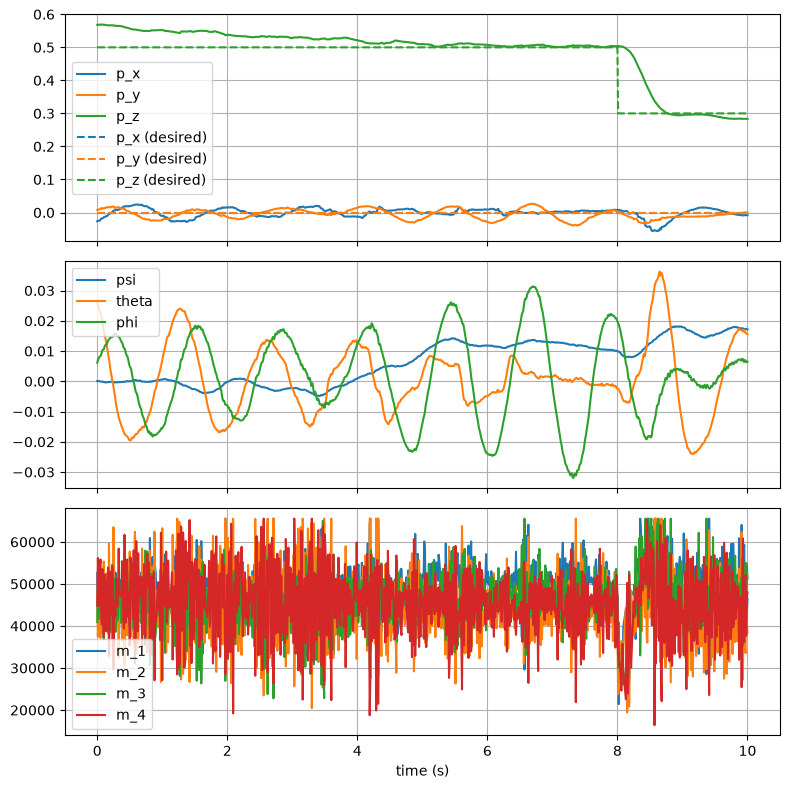

In [180]:
fig, (ax_pos, ax_ori, ax_pow) = plt.subplots(3, 1, figsize=(8, 8), sharex=True, tight_layout=True)
px = ax_pos.plot(t, p_x, label=f'p_x')
py = ax_pos.plot(t, p_y, label=f'p_y')
pz = ax_pos.plot(t, p_z, label=f'p_z')
ax_pos.plot(t, p_x_des, '--', label=f'p_x (desired)', color=px[0].get_color())
ax_pos.plot(t, p_y_des, '--', label=f'p_y (desired)', color=py[0].get_color())
ax_pos.plot(t, p_z_des, '--', label=f'p_z (desired)', color=pz[0].get_color())
ax_pos.legend()
ax_pos.grid()
ax_ori.plot(t, psi, label='psi')
ax_ori.plot(t, theta, label='theta')
ax_ori.plot(t, phi, label='phi')
ax_ori.legend()
ax_ori.grid()
ax_pow.plot(t, m_1, label='m_1')
ax_pow.plot(t, m_2, label='m_2')
ax_pow.plot(t, m_3, label='m_3')
ax_pow.plot(t, m_4, label='m_4')
ax_pow.legend()
ax_pow.grid()
ax_pow.set_xlabel('time (s)')
plt.show()

Show the gains that were used to produce these results.

In [181]:
show_gains(filename)

Control gains, designed 2026-10-23T12:40:30:
tau_x_cmd:     eq   0.0000    p_y  -0.0286    phi   0.0488    v_y  -0.0175    w_x   0.0072  tau_x   3.3824    e_y  -0.0056
tau_y_cmd:     eq   0.0000    p_x   0.0110  theta   0.0236    v_x   0.0076    w_y   0.0039  tau_y   2.2736    e_x   0.0028
    tau_z:     eq   0.0000    psi   0.0030    w_z   0.0008
      f_z:     eq   0.3335    p_z   0.5062    v_z   0.2316    e_z   0.1386


# Section 7. Enable smooth motion


### 7.1 Results of non-smooth square flight


In [186]:
filename = 'square.json'   # <-- FIXME

raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=5.,            
    t_max_offset=3.,           
)

only_in_flight(data_drone, t_interval=10.)

# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

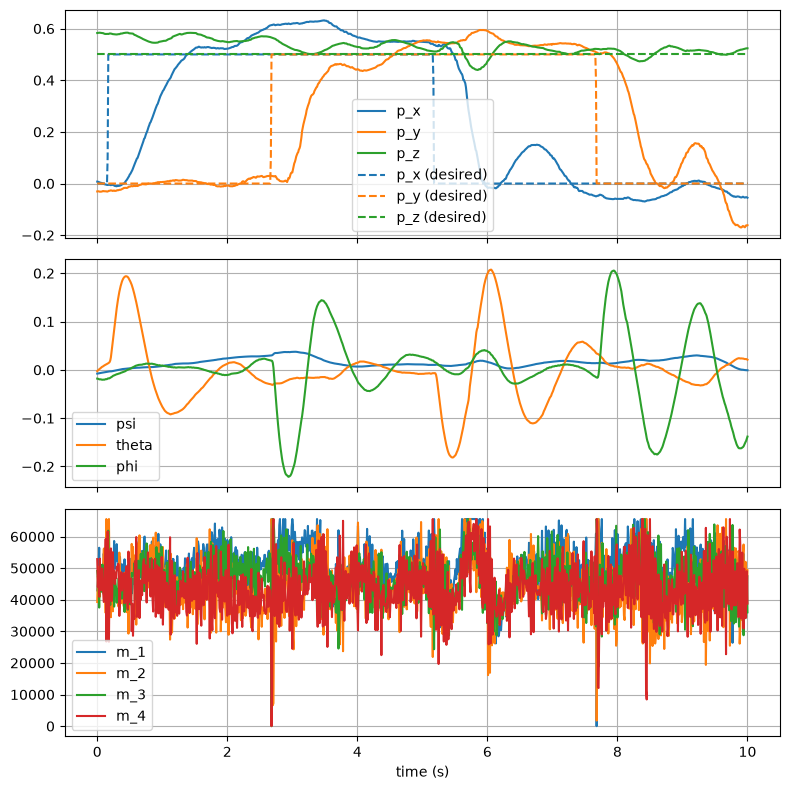

In [187]:
fig, (ax_pos, ax_ori, ax_pow) = plt.subplots(3, 1, figsize=(8, 8), sharex=True, tight_layout=True)
px = ax_pos.plot(t, p_x, label=f'p_x')
py = ax_pos.plot(t, p_y, label=f'p_y')
pz = ax_pos.plot(t, p_z, label=f'p_z')
ax_pos.plot(t, p_x_des, '--', label=f'p_x (desired)', color=px[0].get_color())
ax_pos.plot(t, p_y_des, '--', label=f'p_y (desired)', color=py[0].get_color())
ax_pos.plot(t, p_z_des, '--', label=f'p_z (desired)', color=pz[0].get_color())
ax_pos.legend()
ax_pos.grid()
ax_ori.plot(t, psi, label='psi')
ax_ori.plot(t, theta, label='theta')
ax_ori.plot(t, phi, label='phi')
ax_ori.legend()
ax_ori.grid()
ax_pow.plot(t, m_1, label='m_1')
ax_pow.plot(t, m_2, label='m_2')
ax_pow.plot(t, m_3, label='m_3')
ax_pow.plot(t, m_4, label='m_4')
ax_pow.legend()
ax_pow.grid()
ax_pow.set_xlabel('time (s)')
plt.show()

In [188]:
p_x_rmse = np.sqrt(np.mean((p_x - p_x_des)**2))
p_y_rmse = np.sqrt(np.mean((p_y - p_y_des)**2))
p_z_rmse = np.sqrt(np.mean((p_z - p_z_des)**2))
psi_rmse = np.sqrt(np.mean((psi - 0.)**2))
theta_rmse = np.sqrt(np.mean((theta - 0.)**2))
phi_rmse = np.sqrt(np.mean((phi - 0.)**2))

In [189]:
flight_number = 1
key_changes = ''
print(f'| {flight_number} | {p_x_rmse:.3f} | {p_y_rmse:.3f} | {p_z_rmse:.3f} | {psi_rmse:.3f} | {theta_rmse:.3f} | {phi_rmse:.3f} | {key_changes} |')

| 1 | 0.176 | 0.161 | 0.043 | 0.018 | 0.066 | 0.075 |  |


### 7.2 Results of smooth flight

In [190]:
filename = 'smooth_square.json'   # <-- FIXME

raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=5.,            
    t_max_offset=3.,           
)

only_in_flight(data_drone, t_interval=10.)

# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

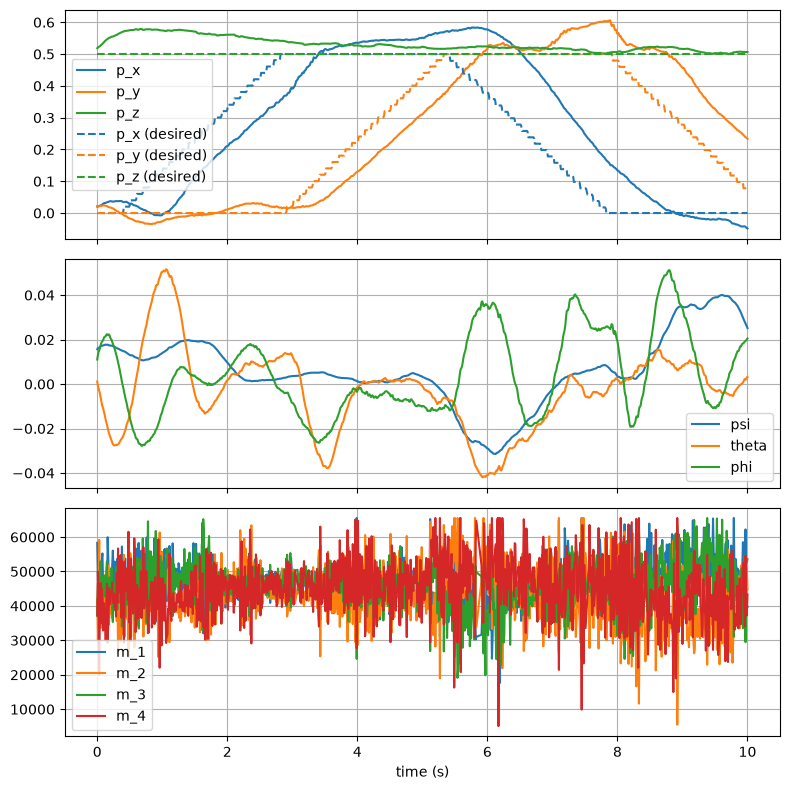

In [191]:
fig, (ax_pos, ax_ori, ax_pow) = plt.subplots(3, 1, figsize=(8, 8), sharex=True, tight_layout=True)
px = ax_pos.plot(t, p_x, label=f'p_x')
py = ax_pos.plot(t, p_y, label=f'p_y')
pz = ax_pos.plot(t, p_z, label=f'p_z')
ax_pos.plot(t, p_x_des, '--', label=f'p_x (desired)', color=px[0].get_color())
ax_pos.plot(t, p_y_des, '--', label=f'p_y (desired)', color=py[0].get_color())
ax_pos.plot(t, p_z_des, '--', label=f'p_z (desired)', color=pz[0].get_color())
ax_pos.legend()
ax_pos.grid()
ax_ori.plot(t, psi, label='psi')
ax_ori.plot(t, theta, label='theta')
ax_ori.plot(t, phi, label='phi')
ax_ori.legend()
ax_ori.grid()
ax_pow.plot(t, m_1, label='m_1')
ax_pow.plot(t, m_2, label='m_2')
ax_pow.plot(t, m_3, label='m_3')
ax_pow.plot(t, m_4, label='m_4')
ax_pow.legend()
ax_pow.grid()
ax_pow.set_xlabel('time (s)')
plt.show()

In [192]:
p_x_rmse = np.sqrt(np.mean((p_x - p_x_des)**2))
p_y_rmse = np.sqrt(np.mean((p_y - p_y_des)**2))
p_z_rmse = np.sqrt(np.mean((p_z - p_z_des)**2))
psi_rmse = np.sqrt(np.mean((psi - 0.)**2))
theta_rmse = np.sqrt(np.mean((theta - 0.)**2))
phi_rmse = np.sqrt(np.mean((phi - 0.)**2))

In [193]:
flight_number = "Smooth Square"
print(f'| {flight_number} | {p_x_rmse:.3f} | {p_y_rmse:.3f} | {p_z_rmse:.3f} | {psi_rmse:.3f} | {theta_rmse:.3f} | {phi_rmse:.3f} |')

| Smooth Square | 0.119 | 0.090 | 0.038 | 0.017 | 0.018 | 0.019 |


### 7.3 Comparison between nonsmooth and smooth flight

| Flight | RMSE in $p_x$ | RMSE in $p_y$ | RMSE in $p_z$ | RMSE in $\psi$ | RMSE in $\theta$ | RMSE in $\phi$ |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: |
| Hover |  0.014 | 0.016 | 0.046 | 0.010 | 0.012 | 0.014 | 
| Square | 0.176 | 0.161 | 0.043 | 0.018 | 0.066 | 0.075 |  
| Smooth Square | 0.119 | 0.090 | 0.038 | 0.017 | 0.018 | 0.019 |

The RMSE of our smooth flight is very close to the rmse of our hover test and square test, whereas the square flight has position RMSEs very different from the hover tes. The smooth square is a happy middle for position RMSE between the square and hover.

By using move_smooth, we have decreased Darcy's position error.

**Modify this cell** to describe three things:

* Your design, in particular your choice of $Q$ and $R$ (e.g., why did you make the choices you did).

**We chose q to not make our R cause over saturatipn, and we chose to adjust our R matrix. Our R matriz was chosen based on a ratio that got results with little wobble or yaw in any direction (after much iteration). Then, we multiplied the entire R matrix by 8 to decrease motor saturation. We used to have over saturation across the test, now it's only at the initial takeoff.**

* Your flight test, in particular your choice of flight trajectory (in words and with relevant code from `flight.py`) and the flight conditions (where was the flight conducted, did you power cycle the drone just before flying, what was the battery level, were you using the active marker deck, etc.).

**Drone went up to .5m and hovered for ten seconds. Drone was charged-- but 5 runs in-- and power cycled, and test was conducted in the drone lab with no active marker deck.**

* Your results (as shown in the plots), in particular your hypotheses about the cause of any failures (e.g., crashed drone) and about what might be done to improve performance.

**theres too much power on the way up, it often drifts randomly**

Please also make clear (with justification) whether or not you believe the results obtained in this flight test are "good enough."

**They're great. We got the full 20 points!**